# HW4: Response Clarity Classification with D3-Agentic Prompting

This notebook implements the D3-Agentic Prompting framework for the CLARITY (QEvasion) dataset.
The task is to classify political question-answer pairs into:
- Clear Reply
- Ambivalent
- Clear Non-Reply

The pipeline consists of four specialized agents running on Qwen/Qwen3.5-0.8B.

# Section 1: Environment Setup

In [1]:
# Install required packages (run only if needed; Kaggle usually has most of these)
!pip install -q -U "transformers>=4.52.0"
!pip install -q "accelerate>=0.31.0" bitsandbytes datasets evaluate scikit-learn pandas numpy matplotlib tqdm
!pip install -q dspy-ai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 90.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 29.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 78.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuml-cu12 26.2.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cud

# Section 2: Imports and Reproducibility

A fixed random seed is set everywhere to ensure full reproducibility of all experiments.

In [2]:
import os, re, gc, json, time, random, warnings
from pathlib import Path
from typing import Any, Dict, List, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from tqdm.auto import tqdm

import torch
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    f1_score,
    classification_report,
    confusion_matrix,
)
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    set_seed,
)

warnings.filterwarnings("ignore")

# ---- Global seed ----
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
set_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("SEED =", SEED)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

SEED = 42
CUDA available: True
GPU: Tesla T4


# Section 3: Dataset Loading and Preprocessing

We load the QEvasion / CLARITY dataset directly from Hugging Face.
The dataset contains political question-answer pairs labelled as:
- Clear Reply
- Ambivalent
- Clear Non-Reply

In [3]:
from datasets import load_dataset

DATASET_NAME = "ailsntua/QEvasion"
dataset = load_dataset(DATASET_NAME)
print(dataset)

train_df = dataset["train"].to_pandas()
test_df  = dataset["test"].to_pandas() if "test" in dataset else None

print("Original train shape:", train_df.shape)
if test_df is not None:
    print("Original test shape:", test_df.shape)

# ---- Column rename ----
COLUMN_RENAME = {
    "question":         "question",
    "interview_answer": "answer",
    "clarity_label":    "label",
    "index":            "id",
}
train_df = train_df.rename(columns=COLUMN_RENAME)
if test_df is not None:
    test_df = test_df.rename(columns=COLUMN_RENAME)

print("\nTrain columns:", train_df.columns.tolist())
if test_df is not None:
    print("Test columns:", test_df.columns.tolist())

README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/3.90M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/259k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/3448 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/308 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['title', 'date', 'president', 'url', 'question_order', 'interview_question', 'interview_answer', 'gpt3.5_summary', 'gpt3.5_prediction', 'question', 'annotator_id', 'annotator1', 'annotator2', 'annotator3', 'inaudible', 'multiple_questions', 'affirmative_questions', 'index', 'clarity_label', 'evasion_label'],
        num_rows: 3448
    })
    test: Dataset({
        features: ['title', 'date', 'president', 'url', 'question_order', 'interview_question', 'interview_answer', 'gpt3.5_summary', 'gpt3.5_prediction', 'question', 'annotator_id', 'annotator1', 'annotator2', 'annotator3', 'inaudible', 'multiple_questions', 'affirmative_questions', 'index', 'clarity_label', 'evasion_label'],
        num_rows: 308
    })
})
Original train shape: (3448, 20)
Original test shape: (308, 20)

Train columns: ['title', 'date', 'president', 'url', 'question_order', 'interview_question', 'answer', 'gpt3.5_summary', 'gpt3.5_prediction', 'question', 'annot

## Label Definitions and Column Discovery

We define the three valid labels, numeric mappings, and string aliases so that any
representation the model or dataset uses can be normalised to the canonical string.

In [4]:
LABELS = ["Clear Reply", "Ambivalent", "Clear Non-Reply"]

NUMERIC_LABEL_MAP = {
    0: "Clear Reply",    1: "Ambivalent",    2: "Clear Non-Reply",
    "0": "Clear Reply",  "1": "Ambivalent",  "2": "Clear Non-Reply",
}

LABEL_ALIASES = {
    "clear reply":     "Clear Reply",
    "clear_reply":     "Clear Reply",
    "reply":           "Clear Reply",
    "clear":           "Clear Reply",
    "ambivalent":      "Ambivalent",
    "ambiguous":       "Ambivalent",
    "partial":         "Ambivalent",
    "partially clear": "Ambivalent",
    "clear non-reply": "Clear Non-Reply",
    "clear non reply": "Clear Non-Reply",
    "clear_non_reply": "Clear Non-Reply",
    "non-reply":       "Clear Non-Reply",
    "non reply":       "Clear Non-Reply",
    "nonreply":        "Clear Non-Reply",
}

QUESTION_CANDIDATES = ["question", "Question", "q", "prompt", "query"]
ANSWER_CANDIDATES   = ["answer", "Answer", "interview_answer", "response", "Response", "reply", "Reply"]
LABEL_CANDIDATES    = ["label", "Label", "clarity_label", "target", "Target", "class", "Class", "clarity", "Clarity"]
ID_CANDIDATES       = ["id", "ID", "Id", "index", "Index"]


def find_column(df, candidates, required=True):
    lower_to_original = {c.lower(): c for c in df.columns}
    for cand in candidates:
        if cand in df.columns:
            return cand
        if cand.lower() in lower_to_original:
            return lower_to_original[cand.lower()]
    if required:
        raise ValueError(f"Could not find any of {candidates}. Existing: {list(df.columns)}")
    return None


def normalize_label(x):
    if pd.isna(x):
        return None
    if x in NUMERIC_LABEL_MAP:
        return NUMERIC_LABEL_MAP[x]
    s = str(x).strip()
    if s in NUMERIC_LABEL_MAP:
        return NUMERIC_LABEL_MAP[s]
    if s in LABELS:
        return s
    key = re.sub(r"\s+", " ", s.lower().replace("_", " ")).strip()
    if key in LABEL_ALIASES:
        return LABEL_ALIASES[key]
    if "non" in key and "reply" in key:
        return "Clear Non-Reply"
    if "ambiv" in key or "ambig" in key or "partial" in key:
        return "Ambivalent"
    if "clear" in key or "reply" in key:
        return "Clear Reply"
    return None


question_col = find_column(train_df, QUESTION_CANDIDATES)
answer_col   = find_column(train_df, ANSWER_CANDIDATES)
label_col    = find_column(train_df, LABEL_CANDIDATES)
id_col       = find_column(train_df, ID_CANDIDATES, required=False)

print("question_col:", question_col)
print("answer_col:  ", answer_col)
print("label_col:   ", label_col)
print("id_col:      ", id_col)

# Normalise labels
train_df = train_df.copy()
train_df["label_norm"] = train_df[label_col].apply(normalize_label)

print("\nLabel distribution:")
print(train_df["label_norm"].value_counts(dropna=False))

# Remove rows where the same question+answer pair has conflicting labels
before = len(train_df)
dupes = train_df[train_df.duplicated(subset=[question_col, answer_col], keep=False)]
conf_idx = dupes.groupby([question_col, answer_col]).filter(
    lambda x: x[label_col].nunique() > 1
).index
train_df = train_df.drop(conf_idx).reset_index(drop=True)
print(f"Removed {before - len(train_df)} conflicting rows. Train size: {len(train_df)}")

# Align test columns
if test_df is not None:
    test_df = test_df.copy()
    tq = find_column(test_df, QUESTION_CANDIDATES)
    ta = find_column(test_df, ANSWER_CANDIDATES)
    if tq != question_col:
        test_df[question_col] = test_df[tq]
    if ta != answer_col:
        test_df[answer_col] = test_df[ta]

display(train_df[[question_col, answer_col, label_col, "label_norm"]].head())

question_col: question
answer_col:   answer
label_col:    label
id_col:       id

Label distribution:
label_norm
Ambivalent         2040
Clear Reply        1052
Clear Non-Reply     356
Name: count, dtype: int64
Removed 24 conflicting rows. Train size: 3424


,question,answer,label,label_norm
0,How would you respond to the accusation that t...,"Well, look, first of all, theI am sincere abou...",Clear Reply,Clear Reply
1,Do you think President Xi is being sincere abo...,"Well, look, first of all, theI am sincere abou...",Ambivalent,Ambivalent
2,Do you believe the country's slowdown and gro...,"Look, I think China has a difficult economic p...",Ambivalent,Ambivalent
3,Are you worried about the meeting between Pre...,"Look, I think China has a difficult economic p...",Ambivalent,Ambivalent
4,Is the President's engagement with Asian coun...,"Well, I hope I get to see Mr. Xi sooner than l...",Clear Reply,Clear Reply


## Exploratory Data Analysis

We inspect the dataset to understand class distribution, and question/answer length
distributions. These subgroups will be used later in the performance-across-subgroups
analysis required by the assignment.

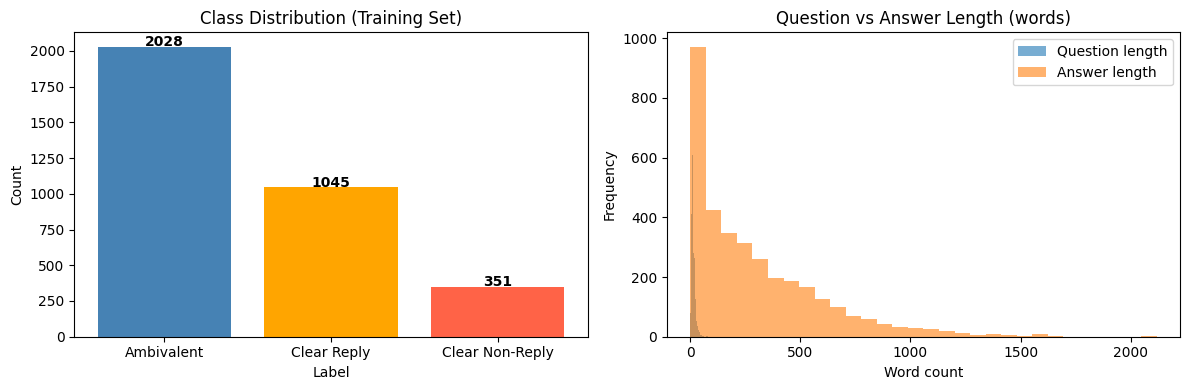

Question length stats:
count    3424.0
mean       14.5
std         8.9
min         1.0
25%         8.0
50%        12.0
75%        19.0
max        80.0
Name: q_len, dtype: float64

Answer length stats:
count    3424.0
mean      293.0
std       300.9
min         1.0
25%        57.0
50%       207.0
75%       439.0
max      2117.0
Name: a_len, dtype: float64


In [5]:
# ---- Class distribution ----
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

counts = train_df["label_norm"].value_counts()
axes[0].bar(counts.index, counts.values, color=["steelblue", "orange", "tomato"])
axes[0].set_title("Class Distribution (Training Set)")
axes[0].set_xlabel("Label")
axes[0].set_ylabel("Count")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 5, str(v), ha="center", fontweight="bold")

# ---- Question / answer lengths ----
train_df["q_len"] = train_df[question_col].astype(str).apply(lambda x: len(x.split()))
train_df["a_len"] = train_df[answer_col].astype(str).apply(lambda x: len(x.split()))

axes[1].hist(train_df["q_len"], bins=30, alpha=0.6, label="Question length")
axes[1].hist(train_df["a_len"], bins=30, alpha=0.6, label="Answer length")
axes[1].set_title("Question vs Answer Length (words)")
axes[1].set_xlabel("Word count")
axes[1].set_ylabel("Frequency")
axes[1].legend()
plt.tight_layout()
plt.savefig("eda_overview.png", dpi=150, bbox_inches="tight")
plt.show()

print("Question length stats:")
print(train_df["q_len"].describe().round(1))
print("\nAnswer length stats:")
print(train_df["a_len"].describe().round(1))

## Train / Validation Split

We perform a stratified 80/20 split. Even though the D3 system is not trained on data,
the split matters: it prevents prompt-overfitting by separating examples used during
prompt design from examples used for final evaluation.

In [6]:
train_part, valid_df = train_test_split(
    train_df,
    test_size=0.20,
    random_state=SEED,
    stratify=train_df["label_norm"],
)
train_part = train_part.reset_index(drop=True)
valid_df   = valid_df.reset_index(drop=True)

print("train_part:", train_part.shape)
print("valid_df:  ", valid_df.shape)
print("\nValidation label distribution:")
print(valid_df["label_norm"].value_counts())

train_part: (2739, 23)
valid_df:   (685, 23)

Validation label distribution:
label_norm
Ambivalent         406
Clear Reply        209
Clear Non-Reply     70
Name: count, dtype: int64


# Section 4: Evaluation Helpers

Centralised evaluation and plotting functions used across all experiments.

In [7]:
def evaluate_predictions(y_true, y_pred, model_name, labels=LABELS):
    acc = accuracy_score(y_true, y_pred)
    p_macro, r_macro, f_macro, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, average="macro", zero_division=0)
    p_weighted, r_weighted, f_weighted, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, average="weighted", zero_division=0)
    return {
        "model":               model_name,
        "accuracy":            round(acc, 4),
        "precision_macro":     round(p_macro, 4),
        "recall_macro":        round(r_macro, 4),
        "f1_macro":            round(f_macro, 4),
        "precision_weighted":  round(p_weighted, 4),
        "recall_weighted":     round(r_weighted, 4),
        "f1_weighted":         round(f_weighted, 4),
    }


def print_full_report(y_true, y_pred, title):
    print("=" * 80)
    print(title)
    print("=" * 80)
    print(classification_report(y_true, y_pred, labels=LABELS, zero_division=0))


def plot_confusion_matrix(y_true, y_pred, title, save_path=None):
    cm = confusion_matrix(y_true, y_pred, labels=LABELS)
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_title(title, fontsize=13)
    ax.set_xlabel("Predicted", fontsize=11)
    ax.set_ylabel("True", fontsize=11)
    ax.set_xticks(range(len(LABELS)))
    ax.set_yticks(range(len(LABELS)))
    ax.set_xticklabels(LABELS, rotation=35, ha="right")
    ax.set_yticklabels(LABELS)
    for i in range(len(LABELS)):
        for j in range(len(LABELS)):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=12)
    fig.colorbar(im, ax=ax)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


# Accumulator for all model results
all_results = []

# Working directory (Kaggle-compatible)
WORK_DIR = Path("/kaggle/working")
WORK_DIR.mkdir(parents=True, exist_ok=True)

print("WORK_DIR:", WORK_DIR)

WORK_DIR: /kaggle/working


# Section 5: Load Qwen/Qwen3.5-0.8B

We load the model once and keep it in memory for all agent calls throughout the notebook.
Greedy decoding (do_sample=False) is used for full reproducibility.

In [8]:
MODEL_NAME = "Qwen/Qwen3.5-0.8B"
D3_VALID_LIMIT      = 100   # main D3 validation run
D3_ABLATION_LIMIT   = 50    # each of the 3 ablation variants
D3_DSPY_VALID_LIMIT = 50    # DSPy-optimised D3 validation run
D3_TEST_LIMIT       = None  # test set (run last, after all validation is done)

MAX_NEW_TOKENS_AGENT    = 180
MAX_NEW_TOKENS_DECISION = 90


def load_qwen_model(model_name=MODEL_NAME):
    tokenizer = AutoTokenizer.from_pretrained(model_name, trust_remote_code=True)
    dtype = torch.float16 if torch.cuda.is_available() else torch.float32
    model = AutoModelForCausalLM.from_pretrained(
        model_name,
        torch_dtype=dtype,
        device_map="auto" if torch.cuda.is_available() else None,
        trust_remote_code=True,
    )
    model.eval()
    if tokenizer.pad_token_id is None:
        tokenizer.pad_token = tokenizer.eos_token
    return tokenizer, model


qwen_tokenizer, qwen_model = load_qwen_model(MODEL_NAME)
print("Loaded:", MODEL_NAME)
print("Device:", next(qwen_model.parameters()).device)

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/12.8M [00:00<?, ?B/s]

...

model.safetensors.index.json: 0.00B [00:00, ?B/s]

model.safetensors-00001-of-00001.safeten(…):   0%|          | 0.00/1.75G [00:00<?, ?B/s]

[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Loaded: Qwen/Qwen3.5-0.8B
Device: cuda:0


# Section 6: Inference and Parsing Helpers

These functions handle chat-template formatting, text generation, JSON extraction,
and label normalisation. Robust parsing is essential because small models like
Qwen3.5-0.8B sometimes truncate or mis-format their JSON output.

In [9]:
def extract_json_object(text):
    """Robustly extract a JSON dict from raw model output."""
    if text is None:
        return {"raw": ""}
    text = text.strip()
    # Strip markdown code fences
    text = re.sub(r"^```(?:json)?", "", text, flags=re.IGNORECASE).strip()
    text = re.sub(r"```$", "", text).strip()
    # Direct parse
    try:
        obj = json.loads(text)
        if isinstance(obj, dict):
            return obj
    except Exception:
        pass
    # Find first {...} block
    match = re.search(r"\{.*\}", text, flags=re.DOTALL)
    if match:
        try:
            obj = json.loads(match.group(0))
            if isinstance(obj, dict):
                return obj
        except Exception:
            pass
    return {"raw": text}


def normalize_prediction_label(text):
    """Map any model output to one of the three valid labels."""
    if text is None:
        return "Ambivalent"
    s = str(text).strip()
    normalized = normalize_label(s)
    if normalized in LABELS:
        return normalized
    key = re.sub(r"\s+", " ", s.lower().replace("_", " ")).strip()
    if "non" in key and "reply" in key:
        return "Clear Non-Reply"
    if "ambivalent" in key or "ambiguous" in key or "partial" in key or "unclear" in key:
        return "Ambivalent"
    if "clear reply" in key:
        return "Clear Reply"
    for label in LABELS:
        if label.lower() in key:
            return label
    return "Ambivalent"


def messages_to_prompt(messages):
    """Apply the model's chat template if available."""
    if hasattr(qwen_tokenizer, "apply_chat_template"):
        return qwen_tokenizer.apply_chat_template(
            messages, tokenize=False, add_generation_prompt=True)
    rendered = ""
    for m in messages:
        rendered += f"{m['role'].upper()}:\n{m['content']}\n\n"
    return rendered + "ASSISTANT:\n"


@torch.inference_mode()
def generate_chat(messages, max_new_tokens=160, repetition_penalty=1.0): 
    prompt = messages_to_prompt(messages)
    inputs = qwen_tokenizer(
        prompt, return_tensors="pt", truncation=True, max_length=4096)
    inputs = {k: v.to(qwen_model.device) for k, v in inputs.items()}
    
    output_ids = qwen_model.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        repetition_penalty=repetition_penalty,  
        do_sample=False,
        temperature=None,
        top_p=None,
        pad_token_id=qwen_tokenizer.pad_token_id,
        eos_token_id=qwen_tokenizer.eos_token_id,
    )
    new_tokens = output_ids[0][inputs["input_ids"].shape[-1]:]
    return qwen_tokenizer.decode(new_tokens, skip_special_tokens=True).strip()

In [10]:
def clean_text(text: str, max_words: int = 300) -> str:
    """Remove transcript noise and cap length before sending to agents."""
    text = re.sub(r'\[.*?\]', '', text)        # remove [inaudible], [laughter] etc.
    text = re.sub(r'\(.*?\)', '', text)        # remove (applause) etc.
    text = re.sub(r'\s+', ' ', text).strip()  # normalize whitespace
    words = text.split()
    if len(words) > max_words:
        text = ' '.join(words[:max_words]) + '...'
    return text

def clean_question(text: str) -> str:
    return clean_text(text, max_words=60)

def clean_answer(text: str) -> str:
    return clean_text(text, max_words=300)

print("Text cleaning helpers defined.")

Text cleaning helpers defined.


# Section 7: D3-Agentic Prompting — Agent Prompts

## Design rationale

The D3 pipeline decomposes the classification task into four specialised subtasks.
Each agent receives a targeted instruction and produces a structured JSON object
that feeds the next stage. This is fundamentally different from repeated voting
over the same prompt.

### Agent 1 — Question Intent Agent
Identifies what information would make an answer "clear" for the target question.
It does NOT look at the answer at all.

### Agent 2 — Answer Content Agent
Extracts what the answer actually says relevant to the question.
It does NOT assign a label.

### Agent 3 — Gap and Evasion Agent
Compares what Agent 1 said is required against what Agent 2 found in the answer.
Categorises the gap severity and evasion type.

### Agent 4 — Decision Agent
Uses all prior outputs to assign the final label with a short justification.

In [11]:
# ============================================================
# AGENT 1: Question Intent Agent
# ============================================================
QUESTION_INTENT_PROMPT = """
You are the Question Intent Agent for a response-clarity classification task.

Important dataset rule:
The TARGET_QUESTION may be only one sub-question extracted from a longer interview question.
Analyze ONLY the TARGET_QUESTION. Do not require the answer to address other sub-questions.

Your task:
Identify exactly what information would make an answer CLEAR for the TARGET_QUESTION.
List at most 3 must_address items. Keep each item concise (under 15 words).

Think in terms of answer requirements:
- Is the question asking for yes/no?
- Is it asking what happened?
- Is it asking why/how something happened?
- Is it asking for a specific action, plan, reason, explanation, stance, or evaluation?
- Is it asking about a named person, event, country, policy, organization, or date?

Return exactly one JSON object and nothing else. No preamble, no markdown fences.

JSON schema:
{
  "question_type": "yes_no|what|why|how|when|where|who|stance|explanation|action_plan|evaluation|other",
  "question_intent": "one sentence describing what the target question asks",
  "must_address": "requirement 1; requirement 2",
  "clear_answer_criteria": "one sentence describing what a clear answer must contain",
  "minimal_sufficient_answer": "short description of the minimum information needed for Clear Reply"
}
""".strip()

# ============================================================
# AGENT 2: Answer Content Agent
# ============================================================
ANSWER_CONTENT_PROMPT = """
You are the Answer Content Agent for a response-clarity classification task.

Important dataset rule:
The answer may respond to a longer interview question, but evaluate only what it says
with respect to the TARGET_QUESTION.

Your task:
Extract what the answer actually says that is relevant to the TARGET_QUESTION.

Rules:
- Do not decide the final label.
- Do not reward political rhetoric unless it answers the target question.
- Do not infer facts not present in the answer.
- An implicit answer is allowed only if the answer gives enough information to resolve the question.
- Keep each list to at most 3 items; each item under 20 words.

Look for:
- Direct answer phrases: yes, no, I did, I did not, we will, because...
- Concrete facts, actions, reasons, explanations, examples, commitments
- Vague but related statements
- Topic shifts or deflections
- Refusals or declines to answer

Return exactly one JSON object and nothing else. No preamble, no markdown fences.

JSON schema:
{
  "relevant_answer_summary": "one sentence summarizing content relevant to the target question",
  "direct_answer_present": true,
  "direct_answer_text": "exact short phrase if present, otherwise empty string",
  "concrete_information": "point 1", "point 2",
  "vague_or_general_information": "point 1",
  "off_target_content": "content that answers a different question",
  "refusal_or_non_answer_signals": "signal 1"
}
""".strip()

# ============================================================
# AGENT 3: Gap and Evasion Agent
# ============================================================
GAP_EVASION_PROMPT = """
You are the Gap and Evasion Agent for response-clarity classification.

You receive:
1. the TARGET_QUESTION
2. the answer
3. the Question Intent Agent output
4. the Answer Content Agent output

Your task:
Compare what the target question REQUIRES (from Agent 1) with what the answer PROVIDES (from Agent 2).

Important distinction:
- Missing small detail but mostly answering -> minor gap.
- Some relevant information but vague, incomplete, generic, or indirect -> partial gap.
- Mostly answering another topic, refusing, or avoiding the target question -> major gap.

Evasion categories:
- explicit_answer: directly answers the target question.
- implicit_answer: not in requested form, but enough information is provided.
- partial_half_answer: answers only part of what was asked.
- general_answer: gives broad values/principles but lacks the requested specifics.
- dodging: avoids the precise question while saying related things.
- deflection: redirects to another issue/person/topic.
- declining_to_answer: refuses, says cannot comment, or avoids due to confidentiality.
- claims_ignorance: says they do not know or cannot assess.
- clarification_only: asks for clarification or corrects framing without answering.
- irrelevant: no meaningful relation to the target question.

Do NOT assign the final top-level label.
Keep each list to at most 3 items; each item under 20 words.
Return exactly one JSON object and nothing else. No preamble, no markdown fences.

JSON schema:
{
  "coverage": "complete|mostly_complete|partial|minimal|none",
  "gap_level": "none|minor|partial|major",
  "best_evasion_category": "explicit_answer|implicit_answer|partial_half_answer|general_answer|dodging|deflection|declining_to_answer|claims_ignorance|clarification_only|irrelevant",
  "missing_requirements": "missing requirement 1",
  "evidence_for_answering": "short evidence from the answer",
  "evidence_for_evasion_or_gap": "short evidence from the answer",
  "gap_explanation": "one concise sentence summarizing the overall gap"
}
""".strip()

# ============================================================
# AGENT 4: Decision Agent
# ============================================================
# DECISION_PROMPT = """
# You are the Decision Agent for CLARITY response classification.

# Assign exactly one final label for how clearly the ANSWER responds to the TARGET_QUESTION.

# Valid labels (use exactly as written):
# 1. Clear Reply
# 2. Ambivalent
# 3. Clear Non-Reply

# Critical rule:
# Judge only the TARGET_QUESTION. If the answer addresses a different sub-question but not
# the target question, this is NOT a Clear Reply.

# Definitions:

# Clear Reply:
# - The answer directly or implicitly provides the information requested by the target question.
# - A yes/no question is Clear Reply if the answer clearly implies yes or no.
# - The answer does not need to be long.
# - The answer may be politically framed, but it must still resolve the target question.

# Ambivalent:
# - The answer contains some relevant information but is incomplete, vague, or only partially responsive.
# - Gives values, background, context, or related claims but does not fully satisfy the question.
# - May answer part of a multi-part question but misses the current target question.
# - Use for borderline cases where there is meaningful relevance but insufficient clarity.

# Clear Non-Reply:
# - The answer does not meaningfully answer the target question.
# - Refuses, claims ignorance, redirects to another topic, or answers a different question entirely.
# - Use when the response gives little or no usable information for the target question.

# Decision rules:
# - coverage complete or mostly_complete AND answer resolves the question -> Clear Reply.
# - coverage partial/minimal but there is relevant information -> Ambivalent.
# - coverage none, or response is mainly refusal/deflection/irrelevant -> Clear Non-Reply.
# - Do NOT classify as Clear Non-Reply only because the answer is indirect.
# - Do NOT classify as Clear Reply only because the answer is fluent or long.
# - Prefer Ambivalent over Clear Non-Reply when answer has relevant but insufficient information.
# - Prefer Ambivalent over Clear Reply when answer is related but lacks the specific stance/action/reason.

# Calibration examples:

# Example A:
# Target question: "Did you support the bill?"
# Answer: "Yes, I voted for it and I still support it."
# Gap: coverage complete; explicit answer.
# Label: Clear Reply.

# Example B:
# Target question: "What specific steps will you take to reduce prices?"
# Answer: "Families are struggling, this is important, and we are working every day."
# Gap: relevant but no specific steps.
# Label: Ambivalent.

# Example C:
# Target question: "Did you meet with the ambassador?"
# Answer: "I am not going to discuss private diplomatic conversations."
# Gap: declining to answer; no requested information.
# Label: Clear Non-Reply.

# Example D:
# Target question: "Why did unemployment increase?"
# Answer: "The economy has faced global pressure, energy shocks, and reduced demand."
# Gap: gives reasons even without saying 'because'.
# Label: Clear Reply.

# Example E:
# Target question: "Do you think President X is sincere?"
# Answer: "I am sincere about improving the relationship."
# Gap: answers the speaker's sincerity, not President X's.
# Label: Ambivalent.

# Return exactly one JSON object and nothing else. No preamble, no markdown fences.

# JSON schema:
# {
#   "label": "Clear Reply|Ambivalent|Clear Non-Reply",
#   "confidence": 0.0,
#   "main_reason": "one concise sentence",
#   "used_rule": "short description of the rule that determined the label"
# }
# """.strip()
DECISION_PROMPT = """You are a political discourse analyst. Your task is to classify a politician's answer to a journalist's question.

You will receive structured analyses from three specialist agents. Use them to inform your decision.

Select one of the following options:
[A] Clear Reply: The politician directly, clearly, and specifically addresses the question.
[B] Ambivalent: The politician engages with the question's topic but provides a vague, hedging, or partial/mixed response.
[C] Clear Non-Reply: The politician completely evades, ignores, changes the subject, or explicitly refuses to answer.

CRITICAL RULES:
- [B] Ambivalent is the most frequent label (~60% of cases). When in doubt between [A] and [B], choose [B].
- Choose [A] ONLY if the answer is direct, specific, and fully addresses what was asked.
- Choose [C] ONLY if there is complete evasion with zero engagement with the question.

Return exactly one JSON object and nothing else.

JSON schema:
{
  "label": "Clear Reply|Ambivalent|Clear Non-Reply",
  "confidence": 0.0,
  "main_reason": "one concise sentence",
  "used_rule": "short description of the rule that determined the label"
}""".strip()
print("All four agent prompts defined.")

All four agent prompts defined.


## Agent Runner Functions

Each function wraps one LLM call with the appropriate prompt, parses the JSON output,
and returns a structured dict. Error handling is built in throughout.

In [12]:
def run_question_intent_agent(question, full_interview_question=None):
    if full_interview_question and full_interview_question.strip() and \
       full_interview_question.strip() != question.strip():
        user_content = (
            f"Full interview question (context):\n{full_interview_question}\n\n"
            f"Target question:\n{question}"
        )
    else:
        user_content = f"Question:\n{question}"
    messages = [
        {"role": "system", "content": QUESTION_INTENT_PROMPT},
        {"role": "user",   "content": user_content},
    ]
    raw = generate_chat(messages, max_new_tokens=MAX_NEW_TOKENS_AGENT)
    obj = extract_json_object(raw)
    obj["raw"] = raw
    return obj
    
def run_answer_content_agent(question, answer):
    messages = [
        {"role": "system", "content": ANSWER_CONTENT_PROMPT},
        {"role": "user",   "content": f"Question:\n{question}\n\nAnswer:\n{answer}"},
    ]
    raw = generate_chat(messages, max_new_tokens=MAX_NEW_TOKENS_AGENT)
    obj = extract_json_object(raw)
    obj["raw"] = raw
    return obj


def run_gap_evasion_agent(question, answer, question_intent, answer_content):
    user_payload = {
        "question":                    question,
        "answer":                      answer,
        "question_intent_agent_output": question_intent,
        "answer_content_agent_output":  answer_content,
    }
    messages = [
        {"role": "system", "content": GAP_EVASION_PROMPT},
        {"role": "user",   "content": json.dumps(user_payload, ensure_ascii=False, indent=2)},
    ]
    raw = generate_chat(messages, max_new_tokens=MAX_NEW_TOKENS_AGENT)
    obj = extract_json_object(raw)
    obj["raw"] = raw
    return obj


def run_decision_agent(question, answer, question_intent, answer_content, gap_evasion):
    user_payload = {
        "question":                      question,
        "answer":                        answer,
        "question_intent_agent_output":   question_intent,
        "answer_content_agent_output":    answer_content,
        "gap_and_evasion_agent_output":   gap_evasion,
    }
    messages = [
        {"role": "system", "content": DECISION_PROMPT},
        {"role": "user",   "content": json.dumps(user_payload, ensure_ascii=False, indent=2)},
    ]
    raw = generate_chat(messages, max_new_tokens=MAX_NEW_TOKENS_DECISION)
    obj = extract_json_object(raw)
    label = normalize_prediction_label(obj.get("label", raw))
    return {
        "label":      label,
        "confidence": obj.get("confidence", None),
        "main_reason": obj.get("main_reason", ""),
        "used_rule":  obj.get("used_rule", ""),
        "raw":        raw,
    }

## Full D3 Pipeline

`run_d3_one` chains all four agents for a single example.
`run_d3_dataframe` applies the pipeline to an entire dataframe with checkpointing.

In [13]:
def run_d3_one(question, answer, full_interview_question=None):
    """Run all four D3 agents for a single question-answer pair."""
    q = clean_question(question)
    a = clean_answer(answer)
    question_intent = run_question_intent_agent(q, full_interview_question=full_interview_question)
    answer_content  = run_answer_content_agent(q, a)
    gap_evasion     = run_gap_evasion_agent(q, a, question_intent, answer_content)
    decision        = run_decision_agent(q, a, question_intent, answer_content, gap_evasion)

    return {
        "d3_question_intent": json.dumps(question_intent, ensure_ascii=False),
        "d3_answer_content":  json.dumps(answer_content,  ensure_ascii=False),
        "d3_gap_evasion":     json.dumps(gap_evasion,     ensure_ascii=False),
        "d3_decision":        json.dumps(decision,        ensure_ascii=False),
        "pred_d3":            decision["label"],
        "d3_confidence":      decision.get("confidence", None),
        "d3_rationale":       decision.get("main_reason", ""),
    }


def run_d3_dataframe(df, output_path, limit=None, checkpoint_every=25):
    """Run D3 over a dataframe, with periodic CSV checkpointing."""
    run_df = df.copy()
    if limit is not None:
        run_df = run_df.head(limit).copy()

    rows = []
    for i, row in tqdm(run_df.iterrows(), total=len(run_df), desc="D3-Agentic Prompting"):
        try:
            full_iq = str(row.get("interview_question", ""))
            out = run_d3_one(
                str(row[question_col]),
                str(row[answer_col]),
                full_interview_question=full_iq,
            )
        except Exception as e:
            out = {
                "d3_question_intent": "",
                "d3_answer_content":  "",
                "d3_gap_evasion":     "",
                "d3_decision":        json.dumps({"error": str(e)}, ensure_ascii=False),
                "pred_d3":            "Ambivalent",
                "d3_confidence":      None,
                "d3_rationale":       f"Fallback after error: {e}",
            }
        rows.append(out)

        if len(rows) % checkpoint_every == 0:
            ckpt = pd.concat(
                [run_df.iloc[:len(rows)].reset_index(drop=True), pd.DataFrame(rows)], axis=1
            )
            ckpt.to_csv(output_path, index=False)
            print(f"Checkpoint saved: {output_path} | rows={len(rows)}")

    result_df = pd.concat(
        [run_df.reset_index(drop=True), pd.DataFrame(rows)], axis=1
    )
    result_df.to_csv(output_path, index=False)
    print("Saved:", output_path)
    return result_df

print("D3 pipeline runner defined.")

D3 pipeline runner defined.


# Section 8: D3 Baseline Run (Original Prompts)

We run the full D3 pipeline on the validation set using the initial prompt design.
This establishes the baseline D3 score before any prompt optimisation.

D3-Agentic Prompting:   0%|          | 0/100 [00:00<?, ?it/s]

Checkpoint saved: /kaggle/working/d3_validation_outputs.csv | rows=25
Checkpoint saved: /kaggle/working/d3_validation_outputs.csv | rows=50
Checkpoint saved: /kaggle/working/d3_validation_outputs.csv | rows=75
Checkpoint saved: /kaggle/working/d3_validation_outputs.csv | rows=100
Saved: /kaggle/working/d3_validation_outputs.csv
D3-Agentic Prompting: Original Prompts
                 precision    recall  f1-score   support

    Clear Reply       0.41      0.38      0.39        29
     Ambivalent       0.63      0.69      0.66        61
Clear Non-Reply       0.00      0.00      0.00        10

       accuracy                           0.53       100
      macro avg       0.34      0.36      0.35       100
   weighted avg       0.50      0.53      0.51       100



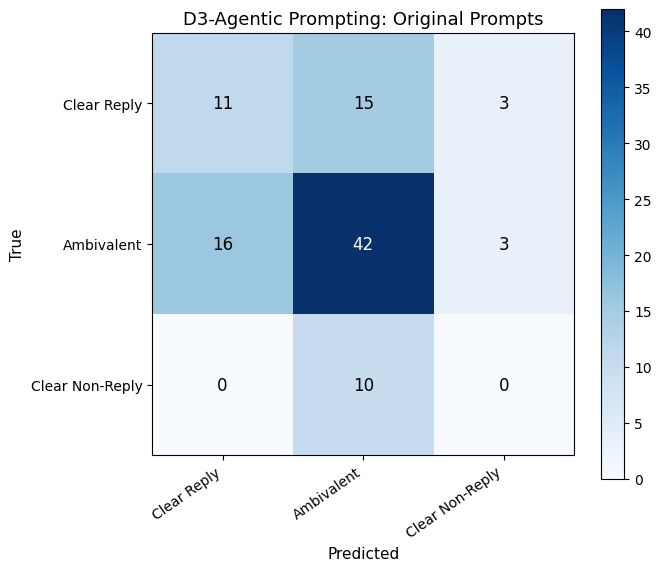

,model,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
0,D3-Agentic (original prompts),0.53,0.3448,0.3559,0.3497,0.5005,0.53,0.5142


In [14]:
d3_valid_path = WORK_DIR / "d3_validation_outputs.csv"

d3_valid_df = run_d3_dataframe(
    valid_df,
    output_path=d3_valid_path,
    limit=D3_VALID_LIMIT,
    checkpoint_every=25,
)

d3_y_true = d3_valid_df["label_norm"].tolist()
d3_y_pred = d3_valid_df["pred_d3"].tolist()

d3_result = evaluate_predictions(d3_y_true, d3_y_pred, "D3-Agentic (original prompts)")

all_results = [r for r in all_results if r["model"] != "D3-Agentic (original prompts)"]
all_results.append(d3_result)

print_full_report(d3_y_true, d3_y_pred, "D3-Agentic Prompting: Original Prompts")
plot_confusion_matrix(d3_y_true, d3_y_pred,
                      "D3-Agentic Prompting: Original Prompts",
                      save_path="cm_d3_original.png")

display(pd.DataFrame(all_results).sort_values("f1_macro", ascending=False).reset_index(drop=True))

# Section 9: Ablation Study — Which Agents Are Necessary?

The instructor's Final Thoughts explicitly ask: which pipeline subparts are necessary?
We run three ablated variants to test this:

- **2-Agent (QI + Decision only)**: Skip Answer Content and Gap/Evasion agents entirely.
  The Decision Agent receives the question, answer, and Question Intent Agent output only.
- **3-Agent (skip QI)**: Skip the Question Intent Agent. Decision uses Answer Content + Gap/Evasion.
- **3-Agent (skip Gap/Evasion)**: Skip Gap/Evasion. Decision uses QI + Answer Content only.

This tells us whether each intermediate agent contributes meaningfully.

Running 2-Agent ablation (QI + Decision only)...


  0%|          | 0/50 [00:00<?, ?it/s]

D3-Ablation: 2-Agent (QI+Decision)
                 precision    recall  f1-score   support

    Clear Reply       0.38      1.00      0.55        19
     Ambivalent       0.00      0.00      0.00        25
Clear Non-Reply       0.00      0.00      0.00         6

       accuracy                           0.38        50
      macro avg       0.13      0.33      0.18        50
   weighted avg       0.14      0.38      0.21        50



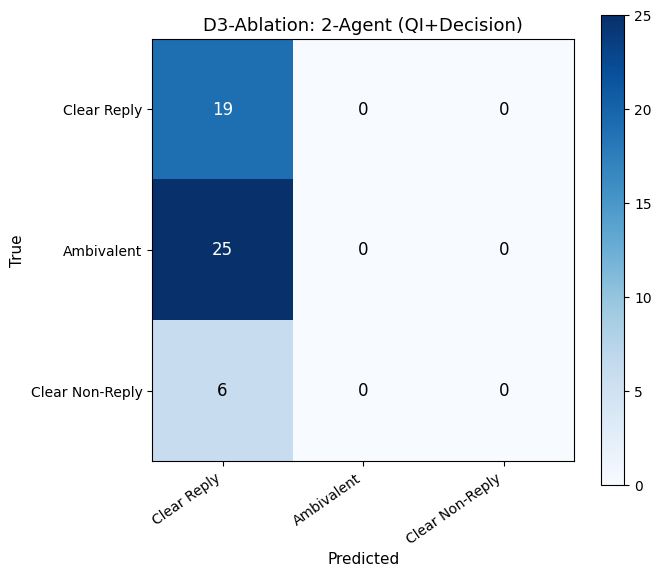

In [15]:
# ---- Ablation variant: 2-Agent (QI + Decision only) ----
DECISION_PROMPT_2AGENT = """
You are the Decision Agent for CLARITY response classification.

You receive only the raw question and answer. Classify directly.

Valid labels (use exactly as written):
1. Clear Reply
2. Ambivalent
3. Clear Non-Reply

Definitions:
Clear Reply: The answer directly or implicitly provides the information requested.
Ambivalent: The answer contains some relevant information but is incomplete or vague.
Clear Non-Reply: The answer does not meaningfully answer the target question.

Return exactly one JSON object and nothing else.
{"label": "Clear Reply|Ambivalent|Clear Non-Reply", "confidence": 0.0, "main_reason": "one sentence"}
""".strip()


def run_d3_2agent_one(question, answer):
    """2-Agent variant: Question Intent -> Decision (skips Agents 2 and 3)."""
    question_intent = run_question_intent_agent(question)

    user_payload = {
        "question":                     question,
        "answer":                       answer,
        "question_intent_agent_output":  question_intent,
    }
    messages = [
        {"role": "system", "content": DECISION_PROMPT_2AGENT},
        {"role": "user",   "content": json.dumps(user_payload, ensure_ascii=False, indent=2)},
    ]
    raw = generate_chat(messages, max_new_tokens=MAX_NEW_TOKENS_DECISION)
    obj = extract_json_object(raw)
    label = normalize_prediction_label(obj.get("label", raw))
    return {"pred": label}


def run_ablation_dataframe(df, agent_fn, limit=None):
    run_df = df.copy()
    if limit is not None:
        run_df = run_df.head(limit).copy()
    preds = []
    for _, row in tqdm(run_df.iterrows(), total=len(run_df)):
        try:
            out = agent_fn(str(row[question_col]), str(row[answer_col]))
            preds.append(out["pred"])
        except Exception:
            preds.append("Ambivalent")
    return preds


# ---- 2-Agent ablation ----
print("Running 2-Agent ablation (QI + Decision only)...")
ablation_2agent_preds = run_ablation_dataframe(valid_df, run_d3_2agent_one, limit=D3_ABLATION_LIMIT)
ab2_true = valid_df["label_norm"].tolist()[:len(ablation_2agent_preds)]
ablation_2agent_result = evaluate_predictions(ab2_true, ablation_2agent_preds, "D3-Ablation: 2-Agent (QI+Decision)")
all_results = [r for r in all_results if r["model"] != "D3-Ablation: 2-Agent (QI+Decision)"]
all_results.append(ablation_2agent_result)
print_full_report(ab2_true, ablation_2agent_preds, "D3-Ablation: 2-Agent (QI+Decision)")
plot_confusion_matrix(ab2_true, ablation_2agent_preds, "D3-Ablation: 2-Agent (QI+Decision)",
                      save_path="cm_ablation_2agent.png")

Running 3-Agent ablation (skip QI)...


  0%|          | 0/50 [00:00<?, ?it/s]

D3-Ablation: 3-Agent (skip QI)
                 precision    recall  f1-score   support

    Clear Reply       0.50      0.37      0.42        19
     Ambivalent       0.50      0.64      0.56        25
Clear Non-Reply       0.00      0.00      0.00         6

       accuracy                           0.46        50
      macro avg       0.33      0.34      0.33        50
   weighted avg       0.44      0.46      0.44        50



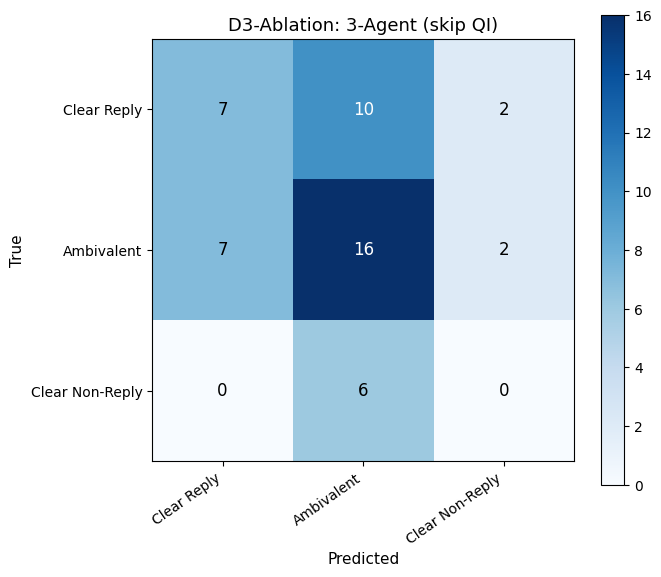

In [16]:
# ---- 3-Agent ablation: skip Question Intent Agent ----
def run_d3_skip_qi_one(question, answer):
    """3-Agent variant: skip QI. Run AC + GE + Decision."""
    answer_content = run_answer_content_agent(question, answer)
    # Gap agent receives empty QI output
    empty_qi = {"question_type": "other", "question_intent": "", "must_address": [],
                 "clear_answer_criteria": "", "minimal_sufficient_answer": ""}
    gap_evasion = run_gap_evasion_agent(question, answer, empty_qi, answer_content)
    decision    = run_decision_agent(question, answer, empty_qi, answer_content, gap_evasion)
    return {"pred": decision["label"]}


print("Running 3-Agent ablation (skip QI)...")
ablation_noqi_preds = run_ablation_dataframe(valid_df, run_d3_skip_qi_one, limit=D3_ABLATION_LIMIT)
noqi_true = valid_df["label_norm"].tolist()[:len(ablation_noqi_preds)]
ablation_noqi_result = evaluate_predictions(noqi_true, ablation_noqi_preds, "D3-Ablation: 3-Agent (skip QI)")
all_results = [r for r in all_results if r["model"] != "D3-Ablation: 3-Agent (skip QI)"]
all_results.append(ablation_noqi_result)
print_full_report(noqi_true, ablation_noqi_preds, "D3-Ablation: 3-Agent (skip QI)")
plot_confusion_matrix(noqi_true, ablation_noqi_preds, "D3-Ablation: 3-Agent (skip QI)",
                      save_path="cm_ablation_noqi.png")

Running 3-Agent ablation (skip Gap/Evasion)...


  0%|          | 0/50 [00:00<?, ?it/s]

D3-Ablation: 3-Agent (skip Gap/Evasion)
                 precision    recall  f1-score   support

    Clear Reply       0.56      0.53      0.54        19
     Ambivalent       0.52      0.64      0.57        25
Clear Non-Reply       0.00      0.00      0.00         6

       accuracy                           0.52        50
      macro avg       0.36      0.39      0.37        50
   weighted avg       0.47      0.52      0.49        50



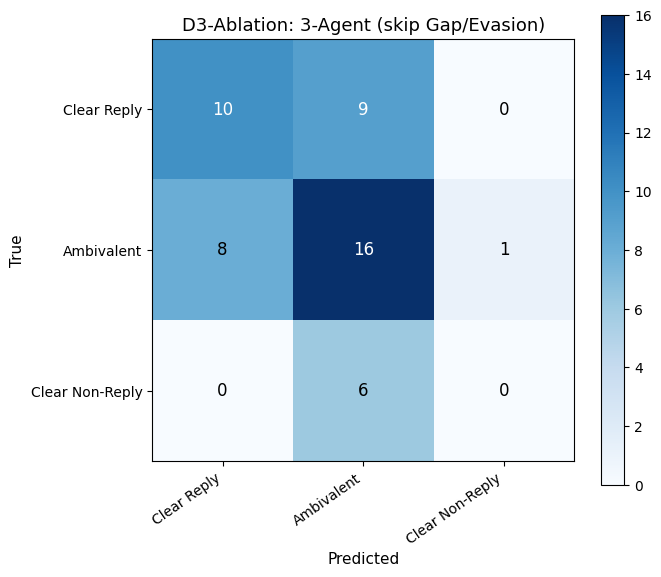


Ablation summary:


,model,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
0,D3-Ablation: 3-Agent (skip Gap/Evasion),0.52,0.3572,0.3888,0.3707,0.4692,0.52,0.4911
1,D3-Agentic (original prompts),0.53,0.3448,0.3559,0.3497,0.5005,0.53,0.5142
2,D3-Ablation: 3-Agent (skip QI),0.46,0.3333,0.3361,0.3285,0.4400,0.46,0.4419
3,D3-Ablation: 2-Agent (QI+Decision),0.38,0.1267,0.3333,0.1836,0.1444,0.38,0.2093


In [17]:
# ---- 3-Agent ablation: skip Gap/Evasion Agent ----
def run_d3_skip_gap_one(question, answer):
    """3-Agent variant: skip Gap/Evasion. Run QI + AC + Decision."""
    question_intent = run_question_intent_agent(question)
    answer_content  = run_answer_content_agent(question, answer)
    # Decision agent receives empty GE output
    empty_ge = {"coverage": "unknown", "gap_level": "unknown", "best_evasion_category": "unknown",
                 "missing_requirements": [], "evidence_for_answering": [],
                 "evidence_for_evasion_or_gap": [], "gap_explanation": ""}
    decision = run_decision_agent(question, answer, question_intent, answer_content, empty_ge)
    return {"pred": decision["label"]}


print("Running 3-Agent ablation (skip Gap/Evasion)...")
ablation_nogap_preds = run_ablation_dataframe(valid_df, run_d3_skip_gap_one, limit=D3_ABLATION_LIMIT)
nogap_true = valid_df["label_norm"].tolist()[:len(ablation_nogap_preds)]
ablation_nogap_result = evaluate_predictions(nogap_true, ablation_nogap_preds, "D3-Ablation: 3-Agent (skip Gap/Evasion)")
all_results = [r for r in all_results if r["model"] != "D3-Ablation: 3-Agent (skip Gap/Evasion)"]
all_results.append(ablation_nogap_result)
print_full_report(nogap_true, ablation_nogap_preds, "D3-Ablation: 3-Agent (skip Gap/Evasion)")
plot_confusion_matrix(nogap_true, ablation_nogap_preds, "D3-Ablation: 3-Agent (skip Gap/Evasion)",
                      save_path="cm_ablation_nogap.png")

print("\nAblation summary:")
display(pd.DataFrame([ablation_2agent_result, ablation_noqi_result, ablation_nogap_result,
                      d3_result]).sort_values("f1_macro", ascending=False).reset_index(drop=True))

# Section 10: Prompt Optimisation with DSPy

DSPy allows automatic prompt refinement using a downstream metric.
Since our intermediate agents do not directly predict the label, we evaluate
whether the full D3 pipeline produces the correct final label (downstream metric).

We use BootstrapFewShot to optimise the Question Intent Agent.

In [18]:
import dspy
from types import SimpleNamespace

# ---- DSPy wrapper for local Qwen model ----
class AttrDict(dict):
    def __getattr__(self, name):
        try:
            return self[name]
        except KeyError:
            raise AttributeError(name)
    def __setattr__(self, name, value):
        self[name] = value


class KaggleQwenDSPyLM(dspy.BaseLM):
    def __init__(self, model_name="local-qwen3.5-0.8b"):
        super().__init__(
            model=model_name,
            model_type="chat",
            cache=False,
            temperature=0.0,
            repetition_penalty=1.15,
            max_new_tokens=200 
        )
        self.model_name = model_name

    def forward(self, prompt=None, messages=None, **kwargs):
        if messages is None:
            messages = [{"role": "user", "content": prompt or ""}]
        
        # Extract max tokens and the repetition penalty
        max_new_tokens = kwargs.get("max_tokens", kwargs.get("max_new_tokens", 256))
        rep_penalty = self.kwargs.get("repetition_penalty", 1.0) 
        
        # Pass both to the generation function
        text = generate_chat(
            messages, 
            max_new_tokens=max_new_tokens, 
            repetition_penalty=rep_penalty 
        )
        return AttrDict({
            "id":      f"chatcmpl-local-{int(time.time() * 1000)}",
            "object":  "chat.completion",
            "created": int(time.time()),
            "model":   self.model_name,
            "choices": [AttrDict({
                "index":         0,
                "message":       AttrDict({"role": "assistant", "content": text}),
                "text":          text,
                "finish_reason": "stop",
            })],
            "usage": AttrDict({"prompt_tokens": 0, "completion_tokens": 0, "total_tokens": 0}),
        })


dspy_lm = KaggleQwenDSPyLM()
dspy.configure(lm=dspy_lm)
print("DSPy configured with local Qwen model.")

DSPy configured with local Qwen model.


In [19]:
# ---- Helper functions for DSPy examples ----
def get_full_question(row):
    if "interview_question" in row:
        return str(row.get("interview_question", ""))
    return str(row.get(question_col, ""))


def get_question_type_hint(row):
    q = str(row.get(question_col, '')).lower()
    if any(w in q for w in ['did you', 'do you', 'will you', 'have you',
                              'are you', 'is it', 'was it', 'would you']):
        return 'yes_no'
    if q.startswith('why'): return 'why'
    if q.startswith('how'): return 'how'
    if q.startswith('what'): return 'what'
    if any(w in q for w in ['think', 'believe', 'support', 'oppose',
                              'agree', 'stance', 'position']):
        return 'stance'
    return 'other'


def get_answer_for_prompt(row):
    if "answer_prompt" in row:
        return str(row.get("answer_prompt", ""))
    return str(row.get(answer_col, ""))


def parse_semicolon_or_lines(x):
    if x is None:
        return []
    s = str(x).strip()
    if not s:
        return []
    parts = re.split(r";|\n|(?:^|\s)-\s+", s)
    parts = [p.strip(" -\u2022\t") for p in parts if p.strip(" -\u2022\t")]
    return parts[:5]


def dspy_qi_prediction_to_dict(pred):
    must_address_raw = getattr(pred, "must_address", "")
    return {
        "question_type":          str(getattr(pred, "question_type", "other")).strip(),
        "question_intent":        str(getattr(pred, "question_intent", "")).strip(),
        "must_address":           parse_semicolon_or_lines(must_address_raw),
        "clear_answer_criteria":  str(getattr(pred, "clear_answer_criteria", "")).strip(),
        "minimal_sufficient_answer": str(getattr(pred, "minimal_sufficient_answer", "")).strip(),
        "raw":    str(pred),
        "source": "dspy_optimized_question_intent",
    }

In [20]:
# ---- DSPy Signature and Module for Question Intent Agent ----
class QuestionIntentSignature(dspy.Signature):
    """
    Analyze the TARGET_QUESTION for response-clarity classification.

    Important:
    The TARGET_QUESTION may be one sub-question extracted from a longer interview question.
    Analyze what information is required to clearly answer the TARGET_QUESTION.
    Do not classify the answer. Do not judge whether the answer is good.
    """

    full_interview_question = dspy.InputField(
        desc="The original full interview question. Use only as context.")
    target_question = dspy.InputField(
        desc="The specific target sub-question that must be evaluated.")
    question_type_hint = dspy.InputField(
        desc="A simple heuristic hint such as yes_no, why, how, what, stance, or other.")

    question_type = dspy.OutputField(
        desc="One of: yes_no, what, why, how, when, where, who, stance, explanation, action_plan, evaluation, other.")
    question_intent = dspy.OutputField(
        desc="One sentence describing exactly what the target question asks.")
    must_address = dspy.OutputField(
        desc="A semicolon-separated string of the specific information a clear answer must provide.")
    clear_answer_criteria = dspy.OutputField(
        desc="One sentence describing what would count as a clear answer.")
    minimal_sufficient_answer = dspy.OutputField(
        desc="The minimum information needed for the answer to be a Clear Reply.")


class DSPyQuestionIntentAgent(dspy.Module):
    def __init__(self):
        super().__init__()
        self.predict = dspy.Predict(QuestionIntentSignature)

    def forward(self, full_interview_question, target_question, question_type_hint,
                answer=None, label=None):
        qi = self.predict(
            full_interview_question=full_interview_question,
            target_question=target_question,
            question_type_hint=question_type_hint,
        )
        return dspy.Prediction(
            question_type=getattr(qi, "question_type", "other"),
            question_intent=getattr(qi, "question_intent", ""),
            must_address=getattr(qi, "must_address", ""),
            clear_answer_criteria=getattr(qi, "clear_answer_criteria", ""),
            minimal_sufficient_answer=getattr(qi, "minimal_sufficient_answer", ""),
        )


print("DSPy Signature and Module defined.")

DSPy Signature and Module defined.


In [21]:
# ---- Downstream metric for DSPy optimisation ----
def question_intent_downstream_metric(example, pred, trace=None):
    """
    The true evaluation is whether the full D3 pipeline produces the correct label.
    Agent 1 output quality is judged by its downstream effect on the final decision.
    """
    question_intent = dspy_qi_prediction_to_dict(pred)
    answer_content  = run_answer_content_agent(example.target_question, example.answer)
    gap_evasion     = run_gap_evasion_agent(
        example.target_question, example.answer, question_intent, answer_content)
    decision        = run_decision_agent(
        example.target_question, example.answer, question_intent, answer_content, gap_evasion)
    predicted_label = normalize_prediction_label(decision["label"])
    gold_label      = normalize_prediction_label(example.label)
    return 1.0 if predicted_label == gold_label else 0.0


# ---- Build balanced training examples for DSPy ----
DSPY_QI_EXAMPLES_PER_CLASS = 4
DSPY_QI_RANDOM_SEED = SEED

def build_balanced_dspy_examples(df, per_class=4):
    examples = []
    for label in LABELS:
        subset = df[df["label_norm"] == label].copy()
        if len(subset) == 0:
            continue
        subset = subset.sample(n=min(per_class, len(subset)), random_state=DSPY_QI_RANDOM_SEED)
        for _, row in subset.iterrows():
            full_q = str(row.get("interview_question", row.get(question_col, "")))
            examples.append(
                dspy.Example(
                    full_interview_question=full_q,
                    target_question=str(row[question_col]),
                    question_type_hint=get_question_type_hint(row),
                    answer=clean_answer(str(row[answer_col])),
                    label=str(row["label_norm"]),
                ).with_inputs("full_interview_question", "target_question",
                              "question_type_hint", "answer")
            )
    random.Random(DSPY_QI_RANDOM_SEED).shuffle(examples)
    return examples

dspy_qi_trainset = build_balanced_dspy_examples(train_part, per_class=DSPY_QI_EXAMPLES_PER_CLASS)
print(f"DSPy training examples: {len(dspy_qi_trainset)}")
print(f"  ({DSPY_QI_EXAMPLES_PER_CLASS} per class x {len(LABELS)} classes = {len(dspy_qi_trainset)} balanced examples)")

DSPy training examples: 12
  (4 per class x 3 classes = 12 balanced examples)


In [22]:
# ---- Run BootstrapFewShot optimisation for Question Intent Agent ----
base_qi_program = DSPyQuestionIntentAgent()

qi_optimizer = dspy.BootstrapFewShot(
    metric=question_intent_downstream_metric,
    max_bootstrapped_demos=4,
    max_labeled_demos=0,
    max_rounds=1,
    max_errors=20,
)

optimized_qi_program = qi_optimizer.compile(
    base_qi_program,
    trainset=dspy_qi_trainset,
)

print("Finished DSPy optimisation for the Question Intent Agent.")

try:
    dspy.inspect_history(n=1)
except Exception as e:
    print("Could not inspect DSPy history:", e)

  0%|          | 0/12 [00:00<?, ?it/s]2026/06/09 18:52:49 ERROR dspy.teleprompt.bootstrap: Failed to run or to evaluate example Example({'full_interview_question': "Q. Thank you, Mr. President. One of your chief allies in the war on terrorism, President Musharraf of Pakistan, has faced so much instability and civil strife recently that there has been talk of declaring a state of emergency. How concerned are you about President Musharraf's situation and whether this might undermine Pakistani efforts against the Taliban and Al Qaida elements in the bordering areas of his country, which have been roundly criticized recently?", 'target_question': 'How concerned are you about whether this might undermine Pakistani efforts against the Taliban and Al Qaida elements in the bordering areas of his country, which have been roundly criticized recently?', 'question_type_hint': 'yes_no', 'answer': "You know, I've seen the reports of what they call an emergency declaration. I have seen no such eviden

Bootstrapped 4 full traces after 6 examples for up to 1 rounds, amounting to 6 attempts.
Finished DSPy optimisation for the Question Intent Agent.




[2026-06-09T18:55:47.424043]

System message:

Your input fields are:
1. `full_interview_question` (str): The original full interview question. Use only as context.
2. `target_question` (str): The specific target sub-question that must be evaluated.
3. `question_type_hint` (str): A simple heuristic hint such as yes_no, why, how, what, stance, or other.
Your output fields are:
1. `question_type` (str): One of: yes_no, what, why, how, when, where, who, stance, explanation, action_plan, evaluation, other.
2. `question_intent` (str): One sentence describing exactly what the target question asks.
3. `must_address` (str): A semicolon-separated string of the specific information a clear answer must provide.
4. `clear_answer_criteria` (str): One sentence describing what would count as a clear answer.
5. `minimal_sufficient_answer` (str): The min

## D3 with DSPy-Optimised Question Intent Agent

We now run the full D3 pipeline replacing the original QI agent with the
DSPy-optimised version and compare the results.

Running D3 with DSPy-optimised Question Intent Agent...


D3-DSPy-Optimised:   0%|          | 0/50 [00:00<?, ?it/s]

Checkpoint | rows=25
Checkpoint | rows=50
Saved: /kaggle/working/d3_dspy_validation_outputs.csv
D3-Agentic: DSPy-Optimised Question Intent Agent
                 precision    recall  f1-score   support

    Clear Reply       0.36      0.26      0.30        19
     Ambivalent       0.45      0.56      0.50        25
Clear Non-Reply       0.20      0.17      0.18         6

       accuracy                           0.40        50
      macro avg       0.34      0.33      0.33        50
   weighted avg       0.39      0.40      0.39        50



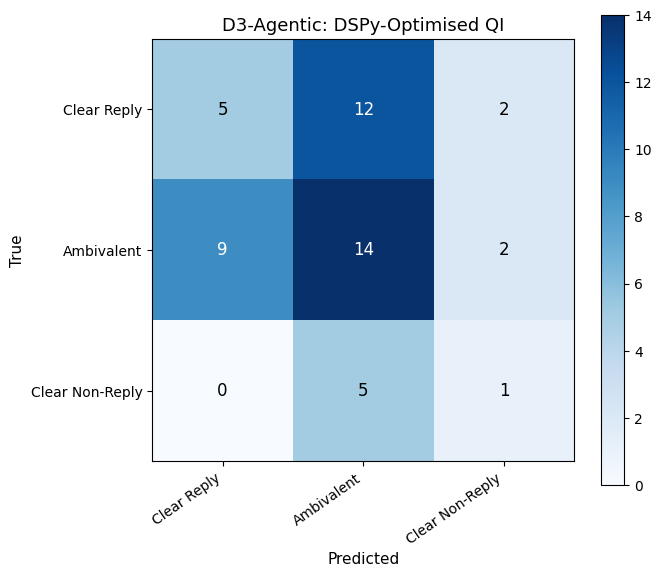

In [23]:
def run_d3_dspy_qi_one(question, answer):
    """Full D3 pipeline using the DSPy-optimised Question Intent Agent."""
    q = clean_question(question)
    a = clean_answer(answer)
    qi_pred = optimized_qi_program(
        full_interview_question=question,  # pass raw for context
        target_question=q,
        question_type_hint="other",
    )
    question_intent = dspy_qi_prediction_to_dict(qi_pred)
    answer_content  = run_answer_content_agent(q, a)
    gap_evasion     = run_gap_evasion_agent(q, a, question_intent, answer_content)
    decision        = run_decision_agent(q, a, question_intent, answer_content, gap_evasion)
    return {
        "d3_question_intent": json.dumps(question_intent, ensure_ascii=False),
        "d3_answer_content":  json.dumps(answer_content,  ensure_ascii=False),
        "d3_gap_evasion":     json.dumps(gap_evasion,     ensure_ascii=False),
        "d3_decision":        json.dumps(decision,        ensure_ascii=False),
        "pred_d3":            decision["label"],
        "d3_confidence":      decision.get("confidence", None),
        "d3_rationale":       decision.get("main_reason", ""),
    }


def run_d3_dspy_dataframe(df, output_path, limit=None, checkpoint_every=25):
    run_df = df.copy()
    if limit is not None:
        run_df = run_df.head(limit).copy()
    rows = []
    for i, row in tqdm(run_df.iterrows(), total=len(run_df), desc="D3-DSPy-Optimised"):
        try:
            out = run_d3_dspy_qi_one(str(row[question_col]), str(row[answer_col]))
        except Exception as e:
            out = {"d3_question_intent": "", "d3_answer_content": "", "d3_gap_evasion": "",
                   "d3_decision": json.dumps({"error": str(e)}),
                   "pred_d3": "Ambivalent", "d3_confidence": None, "d3_rationale": f"Error: {e}"}
        rows.append(out)
        if len(rows) % checkpoint_every == 0:
            ckpt = pd.concat([run_df.iloc[:len(rows)].reset_index(drop=True), pd.DataFrame(rows)], axis=1)
            ckpt.to_csv(output_path, index=False)
            print(f"Checkpoint | rows={len(rows)}")
    result_df = pd.concat([run_df.reset_index(drop=True), pd.DataFrame(rows)], axis=1)
    result_df.to_csv(output_path, index=False)
    print("Saved:", output_path)
    return result_df


print("Running D3 with DSPy-optimised Question Intent Agent...")
d3_dspy_valid_path = WORK_DIR / "d3_dspy_validation_outputs.csv"
d3_dspy_valid_df = run_d3_dspy_dataframe(
    valid_df, output_path=d3_dspy_valid_path, limit=D3_DSPY_VALID_LIMIT, checkpoint_every=25)

dspy_y_true = d3_dspy_valid_df["label_norm"].tolist()
dspy_y_pred = d3_dspy_valid_df["pred_d3"].tolist()

d3_dspy_result = evaluate_predictions(dspy_y_true, dspy_y_pred, "D3-Agentic (DSPy-optimised QI)")
all_results = [r for r in all_results if r["model"] != "D3-Agentic (DSPy-optimised QI)"]
all_results.append(d3_dspy_result)

print_full_report(dspy_y_true, dspy_y_pred, "D3-Agentic: DSPy-Optimised Question Intent Agent")
plot_confusion_matrix(dspy_y_true, dspy_y_pred,
                      "D3-Agentic: DSPy-Optimised QI",
                      save_path="cm_d3_dspy_qi.png")

# Section 11: Performance Across Data Subgroups

The assignment requires analysis across data subgroups. We bin examples by question
length and answer length and compare D3 accuracy across these bins.

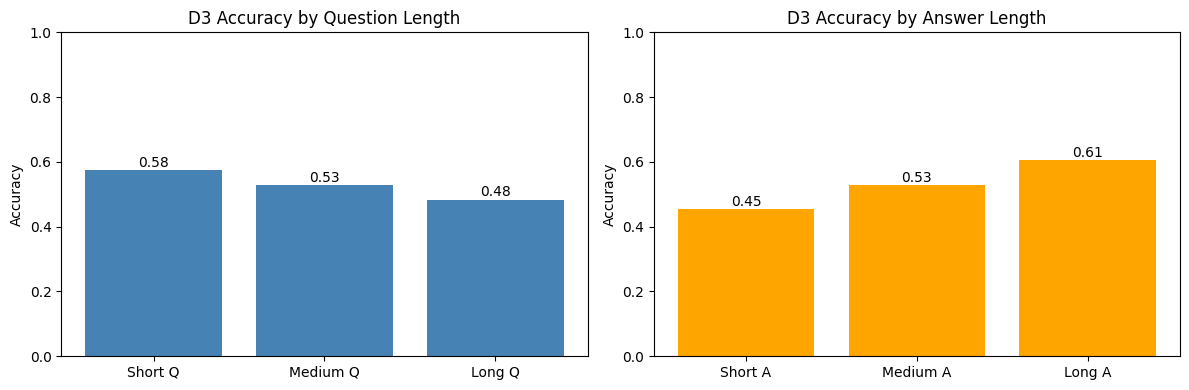

Question length bins:


,Question Length Bin,Accuracy
0,Short Q,0.575758
1,Medium Q,0.527778
2,Long Q,0.483871


Answer length bins:


,Answer Length Bin,Accuracy
0,Short A,0.454545
1,Medium A,0.529412
2,Long A,0.606061



Per-class accuracy:


,True Label,Accuracy
0,Ambivalent,0.688525
1,Clear Non-Reply,0.000000
2,Clear Reply,0.379310


In [24]:
# Use the full D3 validation results
analysis_df = d3_valid_df.copy()
analysis_df["q_len"] = analysis_df[question_col].astype(str).apply(lambda x: len(x.split()))
analysis_df["a_len"] = analysis_df[answer_col].astype(str).apply(lambda x: len(x.split()))
analysis_df["correct"] = (analysis_df["label_norm"] == analysis_df["pred_d3"]).astype(int)

# ---- Question length bins ----
analysis_df["q_bin"] = pd.qcut(analysis_df["q_len"], q=3, labels=["Short Q", "Medium Q", "Long Q"], duplicates="drop")
q_acc = analysis_df.groupby("q_bin", observed=True)["correct"].mean().reset_index()
q_acc.columns = ["Question Length Bin", "Accuracy"]

# ---- Answer length bins ----
analysis_df["a_bin"] = pd.qcut(analysis_df["a_len"], q=3, labels=["Short A", "Medium A", "Long A"], duplicates="drop")
a_acc = analysis_df.groupby("a_bin", observed=True)["correct"].mean().reset_index()
a_acc.columns = ["Answer Length Bin", "Accuracy"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(q_acc["Question Length Bin"], q_acc["Accuracy"], color="steelblue")
axes[0].set_title("D3 Accuracy by Question Length")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1)
for i, v in enumerate(q_acc["Accuracy"]):
    axes[0].text(i, v + 0.01, f"{v:.2f}", ha="center")

axes[1].bar(a_acc["Answer Length Bin"], a_acc["Accuracy"], color="orange")
axes[1].set_title("D3 Accuracy by Answer Length")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1)
for i, v in enumerate(a_acc["Accuracy"]):
    axes[1].text(i, v + 0.01, f"{v:.2f}", ha="center")

plt.tight_layout()
plt.savefig("subgroup_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

print("Question length bins:")
display(q_acc)
print("Answer length bins:")
display(a_acc)

# ---- Per-class accuracy ----
class_acc = analysis_df.groupby("label_norm", observed=True)["correct"].mean().reset_index()
class_acc.columns = ["True Label", "Accuracy"]
print("\nPer-class accuracy:")
display(class_acc)

# Section 12: All-Model Comparison Table and Plots

We now produce the final comparison table across all methods:
- D3-Agentic Prompting (original prompts)
- D3-Agentic Prompting (DSPy-optimised)
- Ablation variants

FULL COMPARISON TABLE


,model,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
0,D3-Ablation: 3-Agent (skip Gap/Evasion),0.52,0.3572,0.3888,0.3707,0.4692,0.52,0.4911
1,D3-Agentic (original prompts),0.53,0.3448,0.3559,0.3497,0.5005,0.53,0.5142
2,D3-Ablation: 3-Agent (skip QI),0.46,0.3333,0.3361,0.3285,0.4400,0.46,0.4419
3,D3-Agentic (DSPy-optimised QI),0.40,0.3363,0.3299,0.3283,0.3855,0.40,0.3870
4,D3-Ablation: 2-Agent (QI+Decision),0.38,0.1267,0.3333,0.1836,0.1444,0.38,0.2093


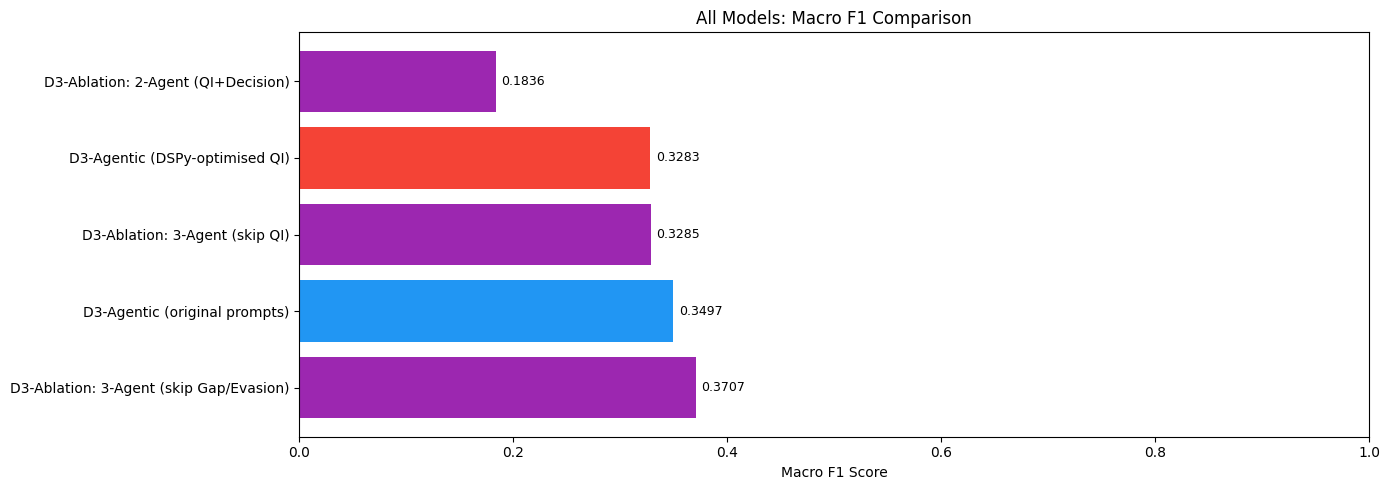

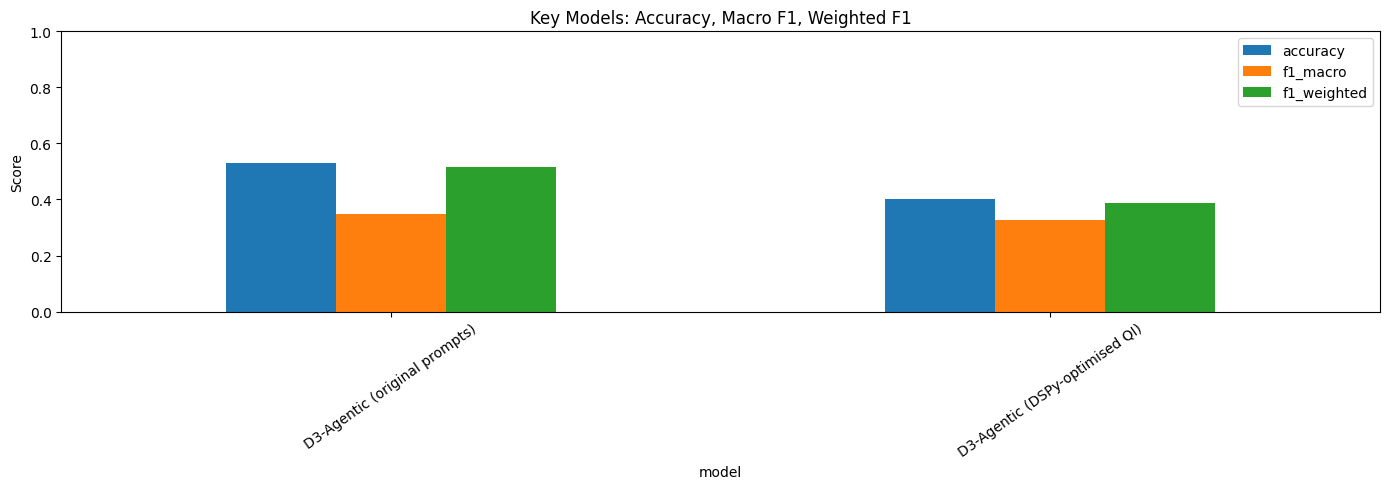

In [25]:
final_results_df = (
    pd.DataFrame(all_results)
    .sort_values("f1_macro", ascending=False)
    .reset_index(drop=True)
)

print("=" * 80)
print("FULL COMPARISON TABLE")
print("=" * 80)
display(final_results_df)

# ---- Bar chart: Macro F1 comparison ----
fig, ax = plt.subplots(figsize=(14, 5))
colors = []
for m in final_results_df["model"]:
    if "Ablation" in m:
        colors.append("#9C27B0")
    elif "DSPy" in m:
        colors.append("#F44336")
    else:
        colors.append("#2196F3")

bars = ax.barh(final_results_df["model"], final_results_df["f1_macro"], color=colors)
ax.set_xlabel("Macro F1 Score")
ax.set_title("All Models: Macro F1 Comparison")
ax.set_xlim(0, 1)
for bar, val in zip(bars, final_results_df["f1_macro"]):
    ax.text(val + 0.005, bar.get_y() + bar.get_height() / 2,
            f"{val:.4f}", va="center", fontsize=9)
plt.tight_layout()
plt.savefig("all_models_f1_macro.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- Multi-metric bar chart for D3 variants vs baselines ----
metrics = ["accuracy", "f1_macro", "f1_weighted"]
key_models = [r for r in all_results if "Ablation" not in r["model"]]
key_df = pd.DataFrame(key_models).set_index("model")[metrics]

key_df.plot(kind="bar", figsize=(14, 5), rot=35)
plt.title("Key Models: Accuracy, Macro F1, Weighted F1")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig("key_models_metrics.png", dpi=150, bbox_inches="tight")
plt.show()

# Section 13: Error Analysis

A central component of the assignment. We analyse:
1. Which class is hardest to predict
2. Recurring linguistic patterns in incorrect predictions
3. How D3 fails differently from the baselines
4. The contribution/harm of individual agents
5. Concrete examples of failures with full intermediate agent output

Total validation examples: 100
Errors: 47 (47.0%)
Correct: 53

Error rate by true label:


,True Label,Error Rate (%)
0,Ambivalent,31.1
1,Clear Reply,62.1
2,Clear Non-Reply,100.0


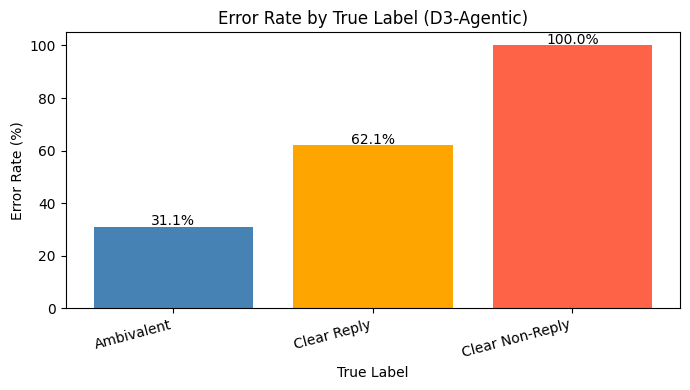

In [26]:
# ---- Misclassified examples ----
errors_df = d3_valid_df[d3_valid_df["label_norm"] != d3_valid_df["pred_d3"]].copy()
correct_df = d3_valid_df[d3_valid_df["label_norm"] == d3_valid_df["pred_d3"]].copy()

print(f"Total validation examples: {len(d3_valid_df)}")
print(f"Errors: {len(errors_df)} ({100 * len(errors_df) / len(d3_valid_df):.1f}%)")
print(f"Correct: {len(correct_df)}")

# ---- Error distribution by true label ----
error_by_class = errors_df["label_norm"].value_counts()
total_by_class = d3_valid_df["label_norm"].value_counts()
error_rate = (error_by_class / total_by_class * 100).round(1)

print("\nError rate by true label:")
err_display = error_rate.reset_index()
err_display.columns = ["True Label", "Error Rate (%)"]
display(err_display)

fig, ax = plt.subplots(figsize=(7, 4))
bar_colors = ["steelblue", "orange", "tomato"]
ax.bar(
    range(len(error_rate)),
    error_rate.values,
    color=bar_colors[:len(error_rate)]
)
ax.set_title("Error Rate by True Label (D3-Agentic)")
ax.set_ylabel("Error Rate (%)")
ax.set_xlabel("True Label")
ax.set_xticks(range(len(error_rate)))
ax.set_xticklabels(error_rate.index, rotation=15, ha="right")
for i, v in enumerate(error_rate.values):
    ax.text(i, v + 0.5, f"{v:.1f}%", ha="center")
plt.tight_layout()
plt.savefig("error_rate_by_class.png", dpi=150, bbox_inches="tight")
plt.show()


Error confusion breakdown:


,True Label,Predicted As,Count
1,Ambivalent,Clear Reply,16
3,Clear Reply,Ambivalent,15
2,Clear Non-Reply,Ambivalent,10
0,Ambivalent,Clear Non-Reply,3
4,Clear Reply,Clear Non-Reply,3


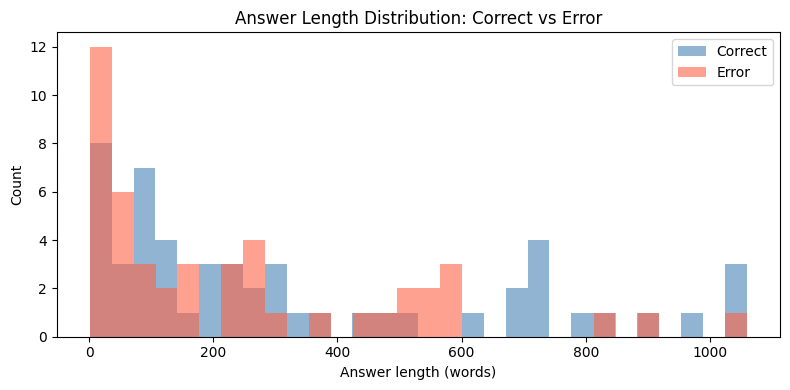


Mean answer length (correct): 337.5 words
Mean answer length (errors):  245.6 words


In [27]:
# ---- Confusion: what does each class get predicted as? ----
confusion_errors = errors_df.groupby(["label_norm", "pred_d3"]).size().reset_index(name="count")
confusion_errors.columns = ["True Label", "Predicted As", "Count"]
print("\nError confusion breakdown:")
display(confusion_errors.sort_values("Count", ascending=False))

# ---- Answer length of errors vs correct ----
errors_df["a_len"]  = errors_df[answer_col].astype(str).apply(lambda x: len(x.split()))
correct_df["a_len"] = correct_df[answer_col].astype(str).apply(lambda x: len(x.split()))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(correct_df["a_len"], bins=30, alpha=0.6, label="Correct", color="steelblue")
ax.hist(errors_df["a_len"],  bins=30, alpha=0.6, label="Error",   color="tomato")
ax.set_title("Answer Length Distribution: Correct vs Error")
ax.set_xlabel("Answer length (words)")
ax.set_ylabel("Count")
ax.legend()
plt.tight_layout()
plt.savefig("answer_len_errors.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\nMean answer length (correct): {correct_df['a_len'].mean():.1f} words")
print(f"Mean answer length (errors):  {errors_df['a_len'].mean():.1f} words")

In [28]:
# ---- Print concrete error examples with full agent trace ----
print("=" * 80)
print("CONCRETE ERROR EXAMPLES WITH FULL AGENT INTERMEDIATE OUTPUT")
print("=" * 80)

for class_label in LABELS:
    class_errors = errors_df[errors_df["label_norm"] == class_label].head(2)
    for _, row in class_errors.iterrows():
        print(f"\nTRUE LABEL: {row['label_norm']}  |  PREDICTED: {row['pred_d3']}")
        print(f"QUESTION:   {str(row[question_col])[:200]}")
        print(f"ANSWER:     {str(row[answer_col])[:300]}")
        print(f"-- Agent 1 (Question Intent) --")
        try:
            qi = json.loads(row["d3_question_intent"])
            print(f"  question_type:   {qi.get('question_type', 'N/A')}")
            print(f"  question_intent: {qi.get('question_intent', 'N/A')}")
            print(f"  must_address:    {qi.get('must_address', 'N/A')}")
        except Exception:
            print(f"  Raw: {row['d3_question_intent'][:200]}")
        print(f"-- Agent 3 (Gap/Evasion) --")
        try:
            ge = json.loads(row["d3_gap_evasion"])
            print(f"  coverage:              {ge.get('coverage', 'N/A')}")
            print(f"  gap_level:             {ge.get('gap_level', 'N/A')}")
            print(f"  best_evasion_category: {ge.get('best_evasion_category', 'N/A')}")
            print(f"  gap_explanation:       {ge.get('gap_explanation', 'N/A')}")
        except Exception:
            print(f"  Raw: {row['d3_gap_evasion'][:200]}")
        print(f"-- Agent 4 (Decision) --")
        try:
            dec = json.loads(row["d3_decision"])
            print(f"  label:      {dec.get('label', 'N/A')}")
            print(f"  main_reason:{dec.get('main_reason', 'N/A')}")
            print(f"  used_rule:  {dec.get('used_rule', 'N/A')}")
        except Exception:
            print(f"  Raw: {row['d3_decision'][:200]}")
        print("-" * 60)

CONCRETE ERROR EXAMPLES WITH FULL AGENT INTERMEDIATE OUTPUT

TRUE LABEL: Clear Reply  |  PREDICTED: Ambivalent
QUESTION:   Should all three individuals be given an opportunity to speak?
ANSWER:     Well, whoever is given a chance. We've delayed it a long time. But they're going to have a big shot at speaking and making their case. And you know what? I could be persuaded also. Okay?
-- Agent 1 (Question Intent) --
  question_type:   yes_no
  question_intent: Should all three individuals be given an opportunity to speak?
  must_address:    Should all three individuals be given an opportunity to speak?
-- Agent 3 (Gap/Evasion) --
  coverage:              mostly_complete
  gap_level:             minor
  best_evasion_category: general_answer
  gap_explanation:       The answer provides a general suggestion that all three individuals should be given an opportunity to speak, but does not explicitly confirm or deny the specific requirement of all three individuals.
-- Agent 4 (Decision) --
  l

## Gap/Evasion Category Distribution

We inspect which evasion categories the Gap/Evasion agent assigns, and whether
certain categories correlate more with errors.

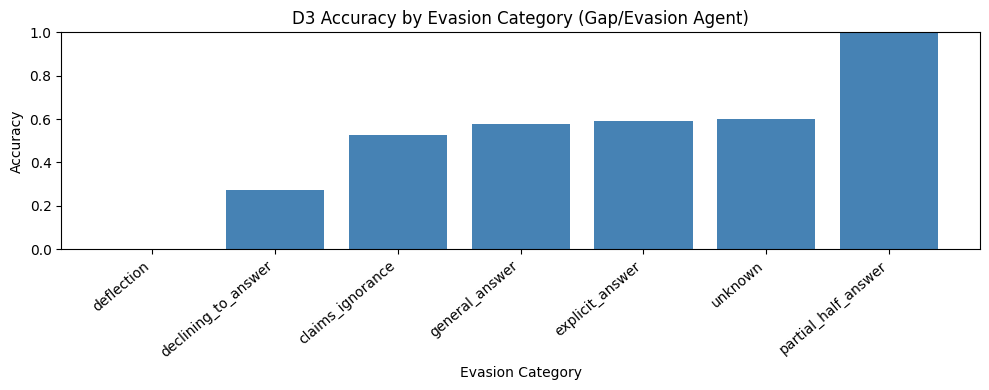

Evasion category breakdown:


,Accuracy,Count
evasion_category,,
deflection,0.000000,1
declining_to_answer,0.272727,11
claims_ignorance,0.527778,36
general_answer,0.578947,19
explicit_answer,0.592593,27
unknown,0.600000,5
partial_half_answer,1.000000,1



Gap level breakdown:


,Accuracy,Count
gap_level,,
major,0.00000,2
minor,0.54023,87
none,0.00000,1
partial,0.60000,5
unknown,0.60000,5


In [29]:
# ---- Extract gap/evasion categories from the full validation run ----
def get_field(json_str, field, default="unknown"):
    try:
        obj = json.loads(json_str)
        return obj.get(field, default)
    except Exception:
        return default


d3_valid_df["evasion_category"] = d3_valid_df["d3_gap_evasion"].apply(
    lambda x: get_field(x, "best_evasion_category"))
d3_valid_df["gap_level"] = d3_valid_df["d3_gap_evasion"].apply(
    lambda x: get_field(x, "gap_level"))
d3_valid_df["coverage"]  = d3_valid_df["d3_gap_evasion"].apply(
    lambda x: get_field(x, "coverage"))
d3_valid_df["correct"]   = (d3_valid_df["label_norm"] == d3_valid_df["pred_d3"]).astype(int)

# Evasion category vs accuracy
evasion_acc = d3_valid_df.groupby("evasion_category", observed=True)["correct"].agg(["mean", "count"])
evasion_acc.columns = ["Accuracy", "Count"]
evasion_acc = evasion_acc.sort_values("Accuracy")

fig, ax = plt.subplots(figsize=(10, 4))
x_pos = range(len(evasion_acc))
ax.bar(x_pos, evasion_acc["Accuracy"], color="steelblue")
ax.set_title("D3 Accuracy by Evasion Category (Gap/Evasion Agent)")
ax.set_ylabel("Accuracy")
ax.set_xlabel("Evasion Category")
ax.set_xticks(x_pos)
ax.set_xticklabels(evasion_acc.index, rotation=40, ha="right")
ax.set_ylim(0, 1)

plt.tight_layout()
plt.savefig("evasion_category_accuracy.png", dpi=150, bbox_inches="tight")
plt.show()

print("Evasion category breakdown:")
display(evasion_acc)

# Gap level vs accuracy
gap_acc = d3_valid_df.groupby("gap_level", observed=True)["correct"].agg(["mean", "count"])
gap_acc.columns = ["Accuracy", "Count"]
print("\nGap level breakdown:")
display(gap_acc)

# Section 14: Test Set Inference and Kaggle Submission

We run the best-performing D3 system on the test set and produce the
submission CSV. The best model is selected based on validation Macro F1.

In [30]:
# ---- Identify best model ----
d3_only_results = [r for r in all_results if "D3-Agentic" in r["model"] and "Ablation" not in r["model"]]

if not d3_only_results:
    raise RuntimeError("No D3-Agentic results found in all_results.")

best_d3 = max(d3_only_results, key=lambda x: x["f1_macro"])

print(f"Best D3 model by validation Macro F1: {best_d3['model']}")
print(f"Validation Macro F1: {best_d3['f1_macro']:.4f}")
print(f"Validation F1 Weighted: {best_d3['f1_weighted']:.4f}")

Best D3 model by validation Macro F1: D3-Agentic (original prompts)
Validation Macro F1: 0.3497
Validation F1 Weighted: 0.5142


In [31]:
# ---- Run best D3 system on test set ----
if test_df is None:
    print("No test set found in the dataset. Skipping test inference.")
else:
    print(f"Running best D3 system on test set ({len(test_df)} examples)...")

    if "DSPy" in best_d3["model"]:
        test_runner = run_d3_dspy_dataframe
    else:
        test_runner = run_d3_dataframe

    d3_test_path = WORK_DIR / "d3_test_outputs.csv"
    d3_test_df = test_runner(
        test_df,
        output_path=d3_test_path,
        limit=D3_TEST_LIMIT,
        checkpoint_every=25,
    )

    print("Test inference complete.")
    print("Test predictions distribution:")
    print(d3_test_df["pred_d3"].value_counts())

    # ---- Sanity check: detect prediction collapse ----
    pred_counts = d3_test_df["pred_d3"].value_counts(normalize=True)
    dominant_ratio = pred_counts.max()
    dominant_class = pred_counts.idxmax()

    if dominant_ratio > 0.75:
        print(f"\nWARNING: Prediction collapse detected.")
        print(f"  '{dominant_class}' = {dominant_ratio:.1%} of predictions.")
        print(f"  Falling back to original D3 pipeline for test inference.")
        d3_test_path = WORK_DIR / "d3_test_outputs_fallback.csv"
        d3_test_df = run_d3_dataframe(
            test_df,
            output_path=d3_test_path,
            limit=D3_TEST_LIMIT,
            checkpoint_every=25,
        )
        print("Fallback test predictions distribution:")
        print(d3_test_df["pred_d3"].value_counts())

Running best D3 system on test set (308 examples)...


D3-Agentic Prompting:   0%|          | 0/308 [00:00<?, ?it/s]

Checkpoint saved: /kaggle/working/d3_test_outputs.csv | rows=25
Checkpoint saved: /kaggle/working/d3_test_outputs.csv | rows=50
Checkpoint saved: /kaggle/working/d3_test_outputs.csv | rows=75
Checkpoint saved: /kaggle/working/d3_test_outputs.csv | rows=100
Checkpoint saved: /kaggle/working/d3_test_outputs.csv | rows=125
Checkpoint saved: /kaggle/working/d3_test_outputs.csv | rows=150
Checkpoint saved: /kaggle/working/d3_test_outputs.csv | rows=175
Checkpoint saved: /kaggle/working/d3_test_outputs.csv | rows=200
Checkpoint saved: /kaggle/working/d3_test_outputs.csv | rows=225
Checkpoint saved: /kaggle/working/d3_test_outputs.csv | rows=250
Checkpoint saved: /kaggle/working/d3_test_outputs.csv | rows=275
Checkpoint saved: /kaggle/working/d3_test_outputs.csv | rows=300
Saved: /kaggle/working/d3_test_outputs.csv
Test inference complete.
Test predictions distribution:
pred_d3
Ambivalent         206
Clear Reply         95
Clear Non-Reply      7
Name: count, dtype: int64


In [32]:
# ---- Produce Kaggle submission CSV ----
EXPECTED_ROWS = 308

if test_df is None:
    print("No test set. Skipping.")
elif "d3_test_df" not in dir():
    print("d3_test_df not defined.")
elif len(d3_test_df) != EXPECTED_ROWS:
    print(f"WARNING: Got {len(d3_test_df)} rows, expected {EXPECTED_ROWS}.")
else:
    submission_df = pd.DataFrame({
        "Id":        d3_test_df[id_col].values,   # actual dataset IDs, not range()
        "Predicted": d3_test_df["pred_d3"].values,
    })

    submission_path = WORK_DIR / "submission_best_d3_agentic_system.csv"
    submission_df.to_csv(submission_path, index=False)

    print("Submission saved to:", submission_path)
    print(f"Rows: {len(submission_df)} / {EXPECTED_ROWS}")
    display(submission_df.head(10))
    display(submission_df["Predicted"].value_counts())

Submission saved to: /kaggle/working/submission_best_d3_agentic_system.csv
Rows: 308 / 308


,Id,Predicted
0,0,Clear Reply
1,1,Ambivalent
2,2,Ambivalent
3,3,Ambivalent
4,4,Ambivalent
5,5,Clear Reply
6,6,Clear Reply
7,7,Clear Reply
8,8,Clear Reply
9,9,Ambivalent


Predicted
Ambivalent         206
Clear Reply         95
Clear Non-Reply      7
Name: count, dtype: int64

# Section 15: Final Summary

Summary of all experiments, best model identification, and key findings.

FINAL RESULTS SUMMARY


,model,accuracy,f1_macro,f1_weighted,precision_macro,recall_macro
0,D3-Ablation: 3-Agent (skip Gap/Evasion),0.52,0.3707,0.4911,0.3572,0.3888
1,D3-Agentic (original prompts),0.53,0.3497,0.5142,0.3448,0.3559
2,D3-Ablation: 3-Agent (skip QI),0.46,0.3285,0.4419,0.3333,0.3361
3,D3-Agentic (DSPy-optimised QI),0.40,0.3283,0.3870,0.3363,0.3299
4,D3-Ablation: 2-Agent (QI+Decision),0.38,0.1836,0.2093,0.1267,0.3333



Best overall model: D3-Ablation: 3-Agent (skip Gap/Evasion)
  Accuracy:          0.5200
  Macro F1:          0.3707
  Weighted F1:       0.4911


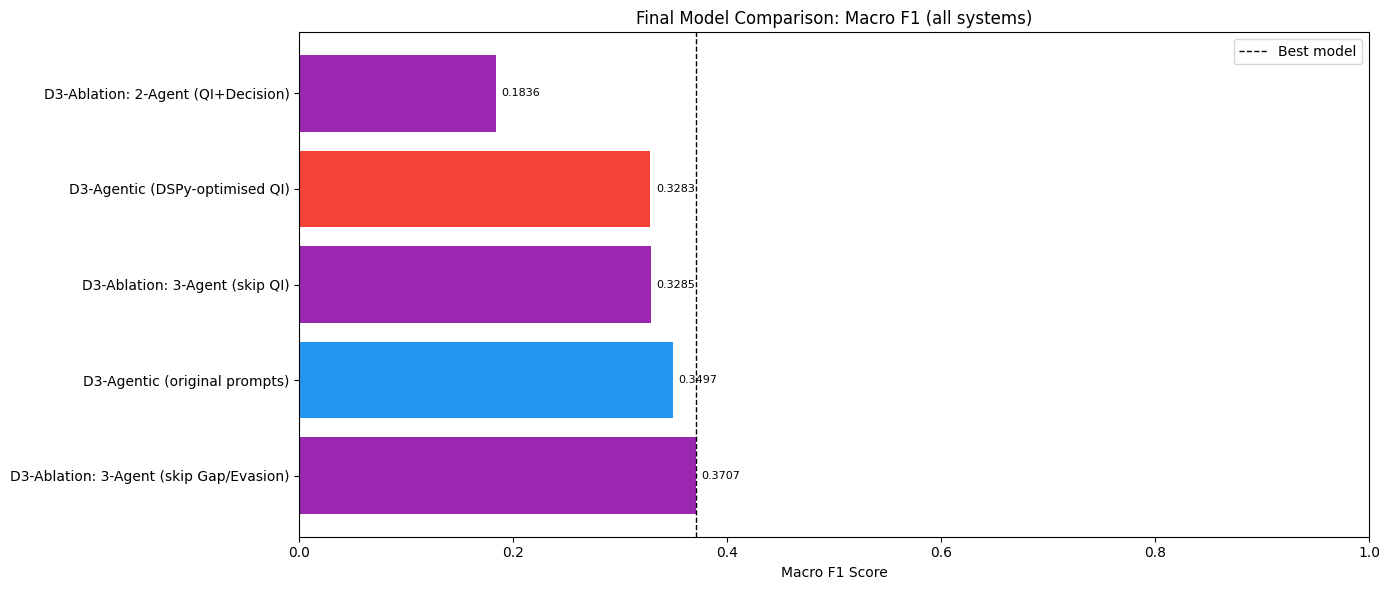


All output files in WORK_DIR:
  __notebook__.ipynb
  all_models_f1_macro.png
  answer_len_errors.png
  cm_ablation_2agent.png
  cm_ablation_nogap.png
  cm_ablation_noqi.png
  cm_d3_dspy_qi.png
  cm_d3_original.png
  d3_dspy_validation_outputs.csv
  d3_test_outputs.csv
  d3_validation_outputs.csv
  eda_overview.png
  error_rate_by_class.png
  evasion_category_accuracy.png
  final_comparison.png
  key_models_metrics.png
  subgroup_analysis.png
  submission_best_d3_agentic_system.csv


In [33]:
print("=" * 80)
print("FINAL RESULTS SUMMARY")
print("=" * 80)

final_df = (
    pd.DataFrame(all_results)
    .sort_values("f1_macro", ascending=False)
    .reset_index(drop=True)
)
display(final_df[["model", "accuracy", "f1_macro", "f1_weighted",
                   "precision_macro", "recall_macro"]])

best_overall = final_df.iloc[0]
print(f"\nBest overall model: {best_overall['model']}")
print(f"  Accuracy:          {best_overall['accuracy']:.4f}")
print(f"  Macro F1:          {best_overall['f1_macro']:.4f}")
print(f"  Weighted F1:       {best_overall['f1_weighted']:.4f}")

# ---- Final macro F1 bar chart (all models, sorted) ----
fig, ax = plt.subplots(figsize=(14, 6))
colors_final = []
for m in final_df["model"]:
    if "Ablation" in m:
        colors_final.append("#9C27B0")
    elif "DSPy" in m:
        colors_final.append("#F44336")
    else:
        colors_final.append("#2196F3")

bars = ax.barh(final_df["model"], final_df["f1_macro"], color=colors_final)
ax.axvline(x=best_overall["f1_macro"], color="black", linestyle="--", linewidth=1, label="Best model")
ax.set_xlabel("Macro F1 Score")
ax.set_title("Final Model Comparison: Macro F1 (all systems)")
ax.set_xlim(0, 1)
for bar, val in zip(bars, final_df["f1_macro"]):
    ax.text(val + 0.005, bar.get_y() + bar.get_height() / 2,
            f"{val:.4f}", va="center", fontsize=8)
ax.legend()
plt.tight_layout()
plt.savefig("final_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nAll output files in WORK_DIR:")
for f in sorted(WORK_DIR.iterdir()):
    print(" ", f.name)